In [ ]:
import os
import sys

from IPython.display import Image, display
from langchain_core.messages import HumanMessage
from langgraph.graph import END, START, MessagesState, StateGraph
from langgraph.prebuilt import ToolNode, tools_condition

sys.path.append(os.path.abspath(os.path.join("..")))
from utils.model import Models

In [7]:
models = Models()
llm = models.create_groq_model()


In [8]:
def multiply(a: int, b: int) -> int:
    """
    Multiply the two integers and return the result
    Args:
        a:First integer
        b:Second integer
    """
    return a * b

In [9]:
llm_with_tools = llm.bind_tools([multiply])

In [10]:
def tool_calling(state: MessagesState):
    return {"messages": llm_with_tools.invoke(state["messages"])}

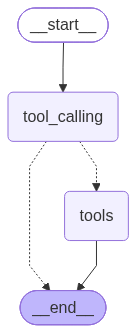

In [11]:
builder = StateGraph(MessagesState)
builder.add_node("tool_calling", tool_calling)
builder.add_node(ToolNode([multiply]))
builder.add_edge(START, "tool_calling")
builder.add_conditional_edges("tool_calling", tools_condition)
builder.add_edge("tool_calling", END)
graph = builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
messages = HumanMessage(content="What is the product of 2 and 3?")
messages = graph.invoke({"messages": [messages]})
for m in messages["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is the product of 2 and 3?
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_e5707276-c505-415a-8237-b1214d6467b5)
 Call ID: fc_e5707276-c505-415a-8237-b1214d6467b5
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6
